# Auditing a frozen encoder for provenance reliance with `physiotrace`

You have a frozen encoder (a physiological foundation model, an imaging
backbone, ...) and a linear task head trained on its embeddings. The data were
recorded on different devices, sites, or protocols, and in your dataset that
**provenance** is associated with the target: one device saw sicker patients,
one site used a different workflow. This tutorial answers one question:

> **Does the task head rely on how the data were recorded?**

Two common measurements do not answer it. Shifted transfer can fail for
reasons that have nothing to do with provenance, and a provenance probe only
shows that provenance is *decodable*, not that the head *uses* it. PhysioTRACE
tests the head's behaviour directly, in four steps:

| Step | What it does |
|---|---|
| **Recover** | measures how decodable provenance is from the embedding |
| **Stress** | reverses only the provenance–target association on the same held-out records and compares a head fitted under the association (*exposed*) with one fitted without it (*control*). The extra degradation of the exposed head is the **excess vulnerability `G`** |
| **Intervene** | removes a provenance direction localized on training data and recomputes `G` |
| **Verify** | certifies that removal only if it beats random directions of the same size **and** costs less utility than a margin `δ` you declare |

Every audit ends in one of three verdicts: **no reliance**, **reliance, remedy
certified**, or **reliance, remedy not certified**.

You will learn how to bring your own embeddings, how to choose the settings,
how to read the report, and which mistakes make an audit misleading.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import physiotrace as pt
from physiotrace.synthetic import make_observational

pd.set_option("display.precision", 4)
print("physiotrace", pt.__version__)

physiotrace 0.1.0.dev0


## 1. Your data

The audit works on **embeddings**, so you need, per recording:

* the frozen embedding (one row of a matrix),
* the binary task label `y` (for example normal vs abnormal),
* the binary provenance label `u` (for example device A vs device B),
* who the recording belongs to (patient or subject) — the **cluster**.

Below we generate a stand-in with a known shortcut: 8,000 ECG-like recordings
from 2,000 patients (four recordings each), two devices, and a device that saw
mostly abnormal patients. **Replace this cell with your own table and
embedding matrix.**

In [2]:
data = make_observational(n=8_000, dim=32, records_per_cluster=4, shared_within_cluster=True, seed=0)

records = pd.DataFrame({
    "patient_id": data.clusters,
    "diagnosis": np.where(data.y == 1, "abnormal", "normal"),
    "device": np.where(data.u == 1, "device B", "device A"),
})
embeddings = data.embeddings          # shape (n_records, d), row-aligned with `records`
records.head()

,patient_id,diagnosis,device
0,0,abnormal,device B
1,0,abnormal,device B
2,0,abnormal,device B
3,0,abnormal,device B
4,1,abnormal,device A


Provenance and target are associated in the data — this is what makes a
shortcut possible:

In [3]:
pd.crosstab(records.device, records.diagnosis, normalize="index")

diagnosis,abnormal,normal
device,,
device A,0.2523,0.7477
device B,0.7695,0.2305


### Split by patient, never by recording

All recordings of one patient must land on the same side of the split.
Otherwise the test set contains near-copies of training records and every
number below is optimistic. Then wrap each side in a `pt.Split`:

In [4]:
rng = np.random.default_rng(0)
patients = records.patient_id.unique()
test_patients = rng.choice(patients, size=len(patients) // 4, replace=False)
is_test = records.patient_id.isin(test_patients).to_numpy()


def split(mask):
    rows = records[mask]
    return pt.Split(embeddings[mask], rows.diagnosis.to_numpy(), rows.device.to_numpy(), clusters=rows.patient_id.to_numpy())


train, test = split(~is_test), split(is_test)
print(f"train: {len(train.y)} recordings, test: {len(test.y)} recordings")

train: 6000 recordings, test: 2000 recordings


`y` and `u` may hold any two labels; the second label in sorted order is
treated as the positive one (`"abnormal"`, `"device B"`).

## 2. Declare the audit before you look

Three numbers decide the verdict. Fix them **before** running the audit on test
data — choosing them after seeing results turns the audit into a search for a
convenient answer.

* `epsilon` — the smallest excess vulnerability `G` (in AUROC) that you would
  call reliance. `0.01` means "a head that loses one more AUROC point than its
  control when the association reverses".
* `delta` — the largest loss of ordinary utility (AUROC of the control head on
  data without the association) that a remedy may cost. Pick the loss you would
  accept in deployment.
* `rank` — how many directions the remedy may remove. Use `1` for a binary
  provenance factor; higher ranks remove more and are refused more often.

`n_random` (random controls, default 100) and `n_bootstrap` (default 2,000)
rarely need changing.

In [5]:
SETTINGS = dict(epsilon=0.01, delta=0.01, rank=1)

## 3. Run the audit

In [6]:
report = pt.audit_observational(train, test, **SETTINGS)
print(report)

PhysioTRACE audit (observational)
  verdict: reliance, remedy certified
  Recover   conditional_accessibility_auroc = 0.9927
  Stress    G = 0.1412 [0.1170, 0.1662]  (epsilon = 0.01; 95% interval)
  Intervene G after rank-1 removal = 0.0017 [-0.0006, 0.0041]  (99% reduction)
  Verify    specific: yes (beats 100/100 random controls)
            safe: yes (control-head AUROC, independent regime change +0.0002 [-0.0001, 0.0004], delta = 0.01)


## 4. Read the report step by step

### Recover: is provenance decodable?

`conditional_accessibility_auroc` is the AUROC of a device probe **within each
diagnosis**, so it is not inflated by the device–diagnosis association. Here
the device is almost perfectly decodable — but that alone says nothing about
whether the head uses it.

### Stress: does the exposed head degrade more than the control?

The audit reweights the *same* test records into regimes that keep both
marginals fixed and change only the device–diagnosis association, from
`aligned` (as in training) through `independent` to `reversed`. The table
holds each head's AUROC in each regime:

In [7]:
regime_order = ["aligned", "intermediate_aligned", "independent", "intermediate_reversed", "reversed"]
aurocs = report.aurocs.pivot_table(index="regime", columns=["representation", "head"], values="auroc").loc[regime_order]
aurocs

representation           full         targeted        
head                  control exposed  control exposed
regime                                                
aligned                0.8923  0.9126   0.8916  0.8917
intermediate_aligned   0.8886  0.8814   0.8882  0.8879
independent            0.8843  0.8411   0.8844  0.8836
intermediate_reversed  0.8801  0.7968   0.8808  0.8795
reversed               0.8766  0.7557   0.8777  0.8761

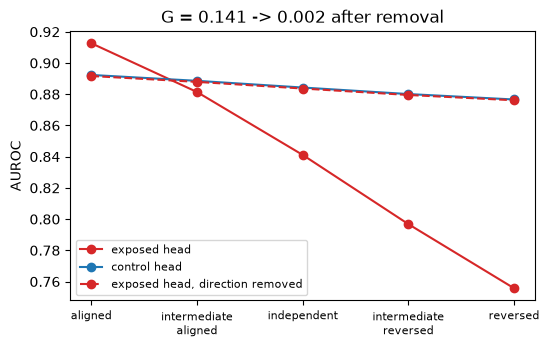

In [8]:
def plot_stress(report, ax=None):
    table = report.aurocs.pivot_table(index="regime", columns=["representation", "head"], values="auroc").loc[regime_order]
    ax = ax or plt.gca()
    x = np.arange(len(regime_order))
    styles = {("full", "exposed"): ("C3", "-", "exposed head"),
              ("full", "control"): ("C0", "-", "control head"),
              ("targeted", "exposed"): ("C3", "--", "exposed head, direction removed")}
    for key, (color, line, label) in styles.items():
        ax.plot(x, table[key], line, color=color, marker="o", label=label)
    ax.set_xticks(x, [r.replace("_", "\n") for r in regime_order], fontsize=8)
    ax.set_ylabel("AUROC")
    ax.set_title(f"G = {report.G:.3f} -> {report.G_after:.3f} after removal")
    ax.legend(fontsize=8)
    return ax


plt.figure(figsize=(6, 3.5))
plot_stress(report)
plt.show()

The control head (blue) is almost flat: it never learned the device, and its
small drift is ordinary change in case mix. The exposed head
(red, solid) is best when the association matches training and worst when it
is reversed. **`G` is how much more the exposed head drops than the control
from aligned to reversed.** Because records, labels, embeddings, and heads are
identical across regimes, `G` measures reliance, not ordinary distribution
shift.

### Intervene: does removing the device direction remove the failure?

The dashed line is the exposed head after one train-localized device direction
is removed from the test embeddings — the heads themselves are not refitted.
It is flat again: `G` falls to about zero.

### Verify: is the removal specific, and is it safe?

*Specific* means the targeted direction reduces `G` more than every random
direction of the same rank and the same share of embedding energy. *Safe* means
the lower confidence bound of the utility change stays above `-delta`.

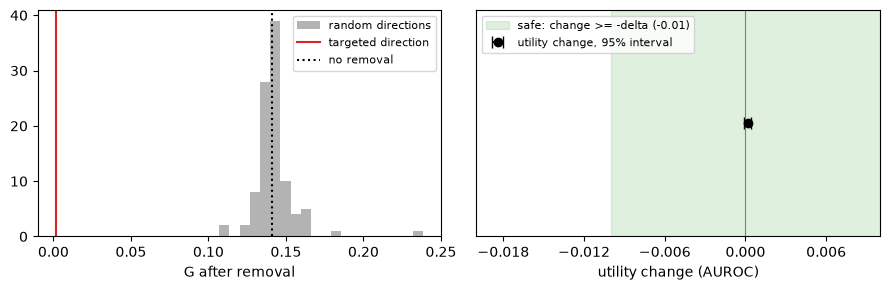

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3))
left.hist(report.G_random, bins=20, color="0.7", label="random directions")
left.axvline(report.G_after, color="C3", label="targeted direction")
left.axvline(report.G, color="k", ls=":", label="no removal")
left.set_xlabel("G after removal")
left.legend(fontsize=8)

low, high = report.utility_change_ci
left_edge = min(-2 * report.delta, low - 0.2 * report.delta)
right_edge = max(report.delta, high + 0.2 * report.delta)
right.axvspan(-report.delta, right_edge, color="C2", alpha=0.15, label=f"safe: change >= -delta ({-report.delta:g})")
right.errorbar([report.utility_change], [0], xerr=[[report.utility_change - low], [high - report.utility_change]],
               fmt="o", color="k", capsize=4, label="utility change, 95% interval")
right.axvline(0, color="0.5", lw=0.8)
right.set_xlim(left_edge, right_edge)
right.xaxis.set_major_locator(plt.MaxNLocator(5))
right.set_yticks([])
right.set_xlabel("utility change (AUROC)")
right.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

Everything the report shows is also available as data:

In [10]:
summary = report.to_dict()          # JSON-serializable; save it next to your results
{key: summary[key] for key in ("verdict", "G", "G_ci", "G_after", "utility_change", "utility_change_ci")}

{'verdict': 'reliance_remedy_certified',
 'G': 0.14120082121338073,
 'G_ci': [0.11702198590817177, 0.16622365262632927],
 'G_after': 0.001712490837321834,
 'utility_change': 0.00015210310639557356,
 'utility_change_ci': [-9.656472205021304e-05, 0.0004304509301390174]}

## 5. The three verdicts and what to do

The same audit on three kinds of data. Each is synthetic with a known answer.

In [11]:
scenarios = {
    "device used as a shortcut": {},
    "device decodable, no association with diagnosis": {"odds_ratio": 1.0},
    "device signal entangled with disease signal": {"entangled": True, "odds_ratio": 20.0, "provenance_strength": 3.0},
}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pt.PhysioTraceWarning)
    for name, options in scenarios.items():
        example_train, example_test = make_observational(n=8_000, seed=1, **options).train_test()
        r = pt.audit_observational(example_train, example_test, **SETTINGS)
        rows.append({"data": name, "verdict": str(r.verdict), "G": r.G,
                     "G after removal": r.G_after if r.decision.reliance else np.nan,
                     "utility change": r.utility_change if r.decision.reliance else np.nan})
pd.DataFrame(rows).set_index("data").round(4)

,verdict,G,G after removal,utility change
data,,,,
device used as a shortcut,"reliance, remedy certified",0.1384,-0.0000,-0.0000
"device decodable, no association with diagnosis",no reliance,0.0001,NaN,NaN
device signal entangled with disease signal,"reliance, remedy not certified",0.0197,-0.0008,-0.1594


* **No reliance.** The head does not depend on the device under this
  association. Note that the device can still be perfectly decodable — that is
  exactly why decodability is not a verdict.
* **Reliance, remedy certified.** The head uses the device, and removing the
  localized direction fixes that without costing more than `delta`. You can
  apply the projection to new embeddings before the head (`subspace.remove`,
  section 8), or refit the head with independence weights.
* **Reliance, remedy not certified.** The head uses the device, but the device
  direction also carries task signal, so removing it costs too much. Do not
  deploy the projection. Collect data in which device and diagnosis are less
  associated, or treat the device as a confounder in the study design.

## 6. Checks

Every report lists validity checks that do not change the verdict but tell you
when its numbers are fragile. With a small test set:

In [12]:
small_train, small_test = make_observational(n=600, dim=16, seed=2).train_test()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pt.PhysioTraceWarning)
    small = pt.audit_observational(small_train, small_test, **SETTINGS)
for finding in small.findings:
    print(finding)

Findings of severity `warning` are also raised as `pt.PhysioTraceWarning` (we
silenced them above to keep the output short). Thresholds live in `pt.Gates`;
`pt.Gates.paper()` gives the stricter gates used in the PhysioTRACE paper.

## 7. Two mistakes that make an audit misleading

### Forgetting who the recordings belong to

Recordings of one patient are similar. If the bootstrap treats them as
independent, the confidence intervals are too narrow and "reliance" can be
declared on noise. Compare the same audit with and without `clusters`:

In [13]:
no_clusters = lambda s: pt.Split(s.embeddings, s.y, s.u)  # noqa: E731
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pt.PhysioTraceWarning)
    naive = pt.audit_observational(no_clusters(train), no_clusters(test), **SETTINGS)
pd.DataFrame({
    "G": [report.G, naive.G],
    "95% interval": [f"[{report.G_ci[0]:.3f}, {report.G_ci[1]:.3f}]", f"[{naive.G_ci[0]:.3f}, {naive.G_ci[1]:.3f}]"],
    "interval width": [np.diff(report.G_ci)[0], np.diff(naive.G_ci)[0]],
}, index=["with patients as clusters", "every recording independent"]).round(4)

,G,95% interval,interval width
with patients as clusters,0.1412,"[0.117, 0.166]",0.0492
every recording independent,0.1412,"[0.127, 0.156]",0.0291


The point estimate is the same, but the interval that ignores patients is
markedly narrower than the one that respects them — it overstates how sure the
audit is. The report flags a missing `clusters` argument as a note.

### Letting a patient appear on both sides of the split

The audit refuses to run:

In [14]:
leaky_test = pt.Split(test.embeddings, test.y, test.u, np.r_[train.clusters[:1], test.clusters[1:]])
try:
    pt.audit_observational(train, leaky_test, **SETTINGS)
except ValueError as error:
    print("ValueError:", error)

ValueError: 1 cluster(s) occur in both train and test (for example 0); keep every patient or subject on one side of the split.


## 8. More options

### Cross-fitting

With limited data, evaluate every record once by rotating the test fold. Keep
each patient inside one fold:

In [15]:
folds = pd.Series(rng.permutation(len(patients)) % 5, index=patients)[records.patient_id].to_numpy()
crossfit = pt.audit_observational_crossfit(
    embeddings, records.diagnosis, records.device, folds=folds, clusters=records.patient_id, **SETTINGS
)
print(crossfit)

PhysioTRACE audit (observational)
  verdict: reliance, remedy certified
  Recover   conditional_accessibility_auroc = 0.9923
  Stress    G = 0.1418 [0.1295, 0.1546]  (epsilon = 0.01; 95% interval)
  Intervene G after rank-1 removal = 0.0006 [-0.0006, 0.0017]  (100% reduction)
  Verify    specific: yes (beats 100/100 random controls)
            safe: yes (control-head AUROC, independent regime change +0.0000 [-0.0001, 0.0001], delta = 0.01)


### Paired views

If every record is observed under every provenance condition — for example
the same EEG under several reference montages — use `pt.audit_paired`. The
association is then induced by design, and provenance is localized from
within-record view contrasts, without task labels:

In [16]:
from physiotrace.synthetic import make_paired

paired_train, paired_val, paired_test = make_paired(seed=2)   # pt.PairedSplit(embeddings, y, views, records)
print(pt.audit_paired(paired_train, paired_test, val=paired_val, delta=0.02))

PhysioTRACE audit (paired)
  verdict: reliance, remedy certified
  Recover   lpi_bits = 0.5815, lpi_max_bits = 1.5850
  Stress    G = 0.0681 [0.0545, 0.0818]  (epsilon = 0.01; 95% interval)
  Intervene G after rank-2 removal = 0.0001 [-0.0006, 0.0008]  (100% reduction)
  Verify    specific: yes (beats 10/10 random controls)
            safe: yes (control-head AUROC, independent coupling change +0.0009 [-0.0008, 0.0025], delta = 0.02)


### Building blocks

Each step is available on its own, for custom designs:

In [17]:
z_train, y_train, u_train = train.embeddings, (train.y == "abnormal").astype(int), (train.u == "device B").astype(int)

# Stress: regimes estimated from training data, and the weights that realize one of them on test data
regimes = pt.observational_regimes(y_train, u_train)
print("aligned odds ratio:", round(pt.weights.odds_ratio(regimes["aligned"]), 2))

# Intervene: the train-localized device direction, applied to new embeddings
subspace, probe = pt.conditional_direction(z_train, y_train, u_train, rank=1)
cleaned = subspace.remove(test.embeddings)
print("removed share of whitened energy:", round(subspace.energy_fraction(z_train), 4))

aligned odds ratio: 9.87
removed share of whitened energy: 0.0382


`pt.lpi(...)` computes calibrated Linear Provenance Information (bits per
recording) when you have a validation split, and `pt.weighted_auroc`,
`pt.cell_weights`, and `pt.random_subspaces` expose the remaining pieces.
Note that `audit_observational` standardizes embeddings with training
statistics before localizing; apply the same standardization when you use the
building blocks for deployment.

## Checklist

1. Split by patient; pass patients as `clusters`.
2. Declare `epsilon`, `delta`, and `rank` before looking at test results.
3. Read the verdict together with `report.findings`.
4. Decodability is not reliance; a certified remedy covers the tested
   association and a linear removal, not every deployment shift.